# Notebook 2 (máy local, OFFLINE) – Fine-tune ViSoBERT / PhoBERT-v2 theo khung code `run_classification.py` của Hugging Face
**Đề tài 21 – ViTHSD** · Môn CMP169 – Trí tuệ Nhân tạo cơ bản

### Nguồn khung code (theo đề bài)
- **Khung huấn luyện:** [`examples/pytorch/text-classification/run_classification.py`](https://github.com/huggingface/transformers/blob/v5.19.0/examples/pytorch/text-classification/run_classification.py)
  của Hugging Face Transformers, bản **v5.19.0** (cùng phiên bản thư viện đồ án dùng; trên nhánh `main` hiện tại thư mục `examples/pytorch` đã bị gỡ).
  Bản gốc nằm trong thư mục `reference/` của project. Giấy phép Apache-2.0.
- **Mô hình:** [`uitnlp/visobert`](https://huggingface.co/uitnlp/visobert), [`vinai/phobert-base-v2`](https://huggingface.co/vinai/phobert-base-v2).
- **GitHub chỉ dùng làm khung code.** Mọi thứ để train lấy từ **Hugging Face**: mô hình gốc `uitnlp/visobert`, `vinai/phobert-base-v2` và dữ liệu `sonlam1102/vithsd`.
  (Repo GitHub của ViSoBERT [github.com/qnamng/ViSoBERT](https://github.com/qnamng/ViSoBERT) chỉ có README giới thiệu mô hình, không có code huấn luyện.)
- **Khung phân tích lỗi (mục 9):** `02_classification.ipynb` của [github.com/nlp-with-transformers/notebooks](https://github.com/nlp-with-transformers/notebooks) (nhóm Hugging Face, Apache-2.0) – cùng khung với Notebook 1.

### Notebook đi theo đúng thứ tự các bước của `main()` trong script

| # | Trong `run_classification.py` | Trong notebook này |
|---|---|---|
| 1 | `HfArgumentParser` đọc tham số dòng lệnh | Ô **Cấu hình** + `TrainingArguments` |
| 2 | `load_dataset("csv"/"json", data_files=...)` | Giữ nguyên: đọc file JSON train/validation/test |
| 3 | Nhãn dạng **list** → `is_multi_label = True`, `get_label_list()` | Giữ nguyên: mỗi bình luận có list nhãn `target#mức` (đúng định dạng của paper) |
| 4 | `AutoConfig(problem_type="multi_label_classification")`, `AutoModelForSequenceClassification` | Giữ nguyên |
| 5 | `preprocess_function()` + `multi_labels_to_ids()` | Giữ nguyên |
| 6 | `compute_metrics()` dùng `evaluate.load("f1", "multilabel")` | **Đổi:** dùng scikit-learn + `common.py`, vì `evaluate` tải script độ đo từ Internet (không chạy offline được) và để cùng độ đo với Notebook 1 |
| 7 | `Trainer(..., DataCollatorWithPadding)` → `train()` → `evaluate()` → `predict()` | Giữ nguyên; **thêm** `EarlyStoppingCallback` + `load_best_model_at_end` (có sẵn trong Trainer) |
| 8 | Dự đoán: logit > 0 → nhãn | Giữ nguyên, **thêm** 1 bước: mỗi target chỉ giữ mức có logit cao nhất (tránh vừa "offensive" vừa "hate") |
| 9 | (script không có) | **Thêm** phân tích lỗi: loss từng bình luận theo khung `forward_pass_with_label()` của `02_classification.ipynb` |

**Cách dùng (máy local có GPU NVIDIA, chạy offline):** chạy Notebook 1 trước. Mô hình gốc ViSoBERT / PhoBERT và dữ liệu phải được tải sẵn từ Hugging Face **một lần** bằng `2_TAI_MO_HINH_GOC.bat` (lúc còn mạng) vào `models/pretrained/` và `data/`.
Ô Cấu hình đặt `MODEL_KEY = "visobert"` → **Run → Run All Cells**; xong đổi `"phobert"` → **Kernel → Restart Kernel and Run All Cells**.
Mô hình sau khi train lưu ở `models/visobert` và `models/phobert` – Notebook 3 và app web dùng luôn 2 thư mục này.
Mỗi mô hình khoảng 5–15 phút trên GPU; **không có GPU thì rất chậm (vài giờ)**.


## 0. Chạy OFFLINE trên máy: bật chế độ offline và **khóa mạng**
Ô dưới chặn mọi kết nối Internet từ Python rồi thử vào một trang web. Thấy dòng *"KHÔNG truy cập được Internet"* là bằng chứng notebook chạy offline.
Dữ liệu đọc từ thư mục `data/`: 3 file train / dev / test **tải từ Hugging Face** `sonlam1102/vithsd` (bằng `2_TAI_MO_HINH_GOC.bat` lúc còn mạng, hoặc có sẵn trong `ViTHSD_ket_qua.zip` từ Colab).


In [1]:

# ===== 0. Bật chế độ offline + KHÓA mạng (chạy ô này ĐẦU TIÊN) =====
import os, sys, socket
from pathlib import Path
os.environ["HF_HUB_OFFLINE"] = "1"            # Hugging Face không gọi Internet
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

def _blocked(*args, **kwargs):
    raise ConnectionError("Đã khóa Internet trong notebook này – mọi thứ phải chạy offline")
socket.socket.connect = _blocked              # chặn mọi kết nối mạng từ Python
socket.create_connection = _blocked
try:
    import urllib.request
    urllib.request.urlopen("https://huggingface.co", timeout=3)
    print("CẢNH BÁO: vẫn truy cập được Internet!")
except Exception as e:
    print("Kiểm tra mạng: KHÔNG truy cập được Internet ->", type(e).__name__, "| notebook chạy offline")

WORK = Path.cwd()
DATA_SOURCE = "Hugging Face – sonlam1102/vithsd (đã tải về thư mục data/)"
print("Thư mục làm việc:", WORK)


Kiểm tra mạng: KHÔNG truy cập được Internet -> URLError | notebook chạy offline
Thư mục làm việc: D:\ViTHSD


## 1. Cấu hình (chỉ cần sửa ô này) – tương ứng tham số dòng lệnh của script

In [2]:
MODEL_KEY = "phobert"            # "visobert" hoặc "phobert"

MAX_SEQ_LENGTH = 128              # --max_seq_length
NUM_TRAIN_EPOCHS = 10             # --num_train_epochs (có early stopping nên thường dừng sớm)
LEARNING_RATE = 3e-5              # --learning_rate
BATCH_SIZE = 32                   # --per_device_train_batch_size (hết VRAM -> 16)
WARMUP = 0.1                      # --warmup_steps (số thực = tỷ lệ trên tổng số bước)
WEIGHT_DECAY = 0.01               # --weight_decay
PATIENCE = 3                      # dừng sớm sau 3 epoch không cải thiện F1 dev
SEED = 42                         # --seed

MODELS = {
    "visobert": {"hf_id": "uitnlp/visobert",       "dir": "visobert",        "segment": False},
    "phobert":  {"hf_id": "vinai/phobert-base-v2", "dir": "phobert-base-v2", "segment": True},   # PhoBERT cần tách từ
}

### Mô hình pre-trained (đọc từ ổ đĩa, không cần mạng)
Tương đương `--model_name_or_path`, nhưng trỏ tới thư mục đã tải sẵn trong `models/pretrained/` thay vì tên trên Hugging Face.

In [3]:
import common
from common import TARGETS, LEVELS, OUT_DIR, MODEL_DIR
OUT_DIR.mkdir(exist_ok=True); MODEL_DIR.mkdir(exist_ok=True)
cfg = MODELS[MODEL_KEY]
PRETRAINED = MODEL_DIR / "pretrained" / cfg["dir"]
if not (PRETRAINED / "config.json").exists():
    raise FileNotFoundError(f"Chưa có mô hình gốc {PRETRAINED}. Khi còn mạng, nhấp đúp 2_TAI_MO_HINH_GOC.bat rồi chạy lại.")
MODEL_NAME_OR_PATH = str(PRETRAINED)                       # --model_name_or_path (thư mục trên máy)
OUTPUT_DIR = MODEL_DIR / MODEL_KEY                         # --output_dir: models/visobert hoặc models/phobert
import torch
print("Mô hình gốc:", MODEL_NAME_OR_PATH, "| kết quả lưu ở:", OUTPUT_DIR)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG có GPU – train sẽ rất chậm")

Mô hình gốc: D:\ViTHSD\models\pretrained\phobert-base-v2 | kết quả lưu ở: D:\ViTHSD\models\phobert
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [4]:
# ===== Thư viện (giống phần import của run_classification.py) =====
import warnings; warnings.filterwarnings("ignore")
import json, random, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from datasets import load_dataset
from transformers import (AutoConfig, AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          EarlyStoppingCallback, EvalPrediction, Trainer, TrainingArguments, set_seed)
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()                      # ẩn cảnh báo "newly initialized classifier" (bình thường)

set_seed(SEED)                                        # như script: set_seed(training_args.seed)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG có – sẽ rất chậm")

GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 2. Chuẩn bị dữ liệu theo định dạng mà script yêu cầu
Script đọc file CSV/JSON có cột **`sentence`** (văn bản) và **`label`**. Với bài toán multi-label, `label` là một **list**.
Mỗi bình luận được đổi thành list nhãn dạng `target#mức` – đúng định dạng trong paper, ví dụ `["individual#hate", "groups#clean"]`.
Mức 0 (không nhắc) không tạo nhãn. Dùng **cùng** hàm làm sạch với Notebook 1 (`common.load_and_clean`) để so sánh công bằng.

In [5]:
train, dev, test, clean_report = common.load_and_clean()

segment = None
if cfg["segment"]:
    from underthesea import word_tokenize            # PhoBERT cần văn bản đã tách từ: "khởi nghiệp" -> "khởi_nghiệp"
    segment = lambda s: word_tokenize(s, format="text") if s else s

def to_records(df):
    """Mỗi dòng -> {"sentence": văn bản, "label": [list nhãn target#mức]}."""
    texts = df["text"].tolist()
    if segment:
        texts = [segment(t) for t in texts]
    labels = [[f"{t}#{LEVELS[v]}" for t, v in zip(TARGETS, row) if v > 0] for row in df[TARGETS].to_numpy()]
    return pd.DataFrame({"sentence": texts, "label": labels})

HF_DATA = common.DATA_DIR / f"hf_{MODEL_KEY}"
HF_DATA.mkdir(exist_ok=True)
data_files = {}
for split, df in [("train", train), ("validation", dev), ("test", test)]:
    to_records(df).to_json(HF_DATA / f"{split}.json", orient="records", lines=True, force_ascii=False)
    data_files[split] = str(HF_DATA / f"{split}.json")
print(open(data_files["train"], encoding="utf-8").readline())

# ----- Giống script: raw_datasets = load_dataset("json", data_files=data_files) -----
raw_datasets = load_dataset("json", data_files=data_files)
raw_datasets

Train: 7000 -> 6785 dòng (bỏ 4 dòng lỗi, 76 dòng trùng, 135 dòng trùng với dev/test) | dev 1201 | test 1800
{"sentence":"Chào nhà_báo vũ_hoàng_Lân . Chào_danh hài_vũ_trụ trần tiger : - )","label":["individual#offensive","groups#clean"]}



Generating train split: 6785 examples [00:00, 482328.61 examples/s]
Generating validation split: 1201 examples [00:00, 169482.51 examples/s]
Generating test split: 1800 examples [00:00, 299676.39 examples/s]


DatasetDict({
    train: Dataset({
        features: ['sentence', 'label'],
        num_rows: 6785
    })
    validation: Dataset({
        features: ['sentence', 'label'],
        num_rows: 1201
    })
    test: Dataset({
        features: ['sentence', 'label'],
        num_rows: 1800
    })
})

## 3. Danh sách nhãn – `get_label_list()` (chép từ script)

In [6]:
def get_label_list(raw_dataset, split="train") -> list[str]:
    """Get the list of labels from a multi-label dataset"""
    if isinstance(raw_dataset[split]["label"][0], list):
        label_list = [label for sample in raw_dataset[split]["label"] for label in sample]
        label_list = list(set(label_list))
    else:
        label_list = raw_dataset[split].unique("label")
    label_list = [str(label) for label in label_list]
    return label_list

# Script kiểm tra features["label"].dtype == "list"; datasets 5.x đổi kiểu feature nên kiểm tra trực tiếp giá trị
is_multi_label = isinstance(raw_datasets["train"]["label"][0], list)
label_list = get_label_list(raw_datasets, split="train")
for split in ["validation", "test"]:                   # như script: gộp nhãn chỉ có ở dev/test
    label_list += list(set(get_label_list(raw_datasets, split=split)) - set(label_list))
label_list.sort()
num_labels = len(label_list)
print("is_multi_label =", is_multi_label, "| num_labels =", num_labels)
print(label_list)

is_multi_label = True | num_labels = 15
['groups#clean', 'groups#hate', 'groups#offensive', 'individual#clean', 'individual#hate', 'individual#offensive', 'politics#clean', 'politics#hate', 'politics#offensive', 'race/ethnicity#clean', 'race/ethnicity#hate', 'race/ethnicity#offensive', 'religion/creed#clean', 'religion/creed#hate', 'religion/creed#offensive']


## 4. Config, tokenizer, mô hình – `AutoConfig` + `AutoModelForSequenceClassification` (như script)

In [7]:
config = AutoConfig.from_pretrained(MODEL_NAME_OR_PATH, num_labels=num_labels, finetuning_task="text-classification")
config.problem_type = "multi_label_classification"    # -> loss BCEWithLogits, mỗi nhãn 1 sigmoid
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME_OR_PATH)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME_OR_PATH, config=config)

label_to_id = {v: i for i, v in enumerate(label_list)}
model.config.label2id = label_to_id
model.config.id2label = {i: l for l, i in label_to_id.items()}

# Script: max_seq_length = min(--max_seq_length, tokenizer.model_max_length)
max_seq_length = min(MAX_SEQ_LENGTH, tokenizer.model_max_length, 256 if MODEL_KEY == "phobert" else 512)
print(type(model).__name__, f"| {sum(p.numel() for p in model.parameters())/1e6:.1f} triệu tham số | max_seq_length = {max_seq_length}")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 20149.19it/s]

RobertaForSequenceClassification | 135.0 triệu tham số | max_seq_length = 128


## 5. Token hóa – `preprocess_function()` + `multi_labels_to_ids()` (như script)

In [8]:
def multi_labels_to_ids(labels: list[str]) -> list[float]:
    ids = [0.0] * len(label_to_id)  # BCELoss requires float as target type
    for label in labels:
        ids[label_to_id[label]] = 1.0
    return ids

def preprocess_function(examples):
    # padding=False: đệm động theo từng batch (DataCollatorWithPadding), như mặc định của script
    result = tokenizer(examples["sentence"], padding=False, max_length=max_seq_length, truncation=True)
    result["label"] = [multi_labels_to_ids(l) for l in examples["label"]]
    return result

raw_datasets = raw_datasets.map(preprocess_function, batched=True, desc="Running tokenizer on dataset")
train_dataset = raw_datasets["train"].shuffle(seed=SEED)          # --shuffle_train_dataset
eval_dataset = raw_datasets["validation"]
predict_dataset = raw_datasets["test"]
# Thêm 1 tập con của train để theo dõi overfitting (so F1 train với F1 dev mỗi epoch)
train_sub = raw_datasets["train"].shuffle(seed=SEED).select(range(min(1500, len(raw_datasets["train"]))))

lens = np.array([len(x) for x in raw_datasets["train"]["input_ids"]])
print(f"Số token/bình luận: trung bình {lens.mean():.1f}, 95% <= {np.percentile(lens, 95):.0f}, "
      f"bị cắt ở {max_seq_length}: {(lens >= max_seq_length).mean():.2%}")
print("Ví dụ token:", tokenizer.convert_ids_to_tokens(train_dataset[0]["input_ids"])[:20])

Running tokenizer on dataset: 100%|██████████| 1800/1800 [00:00<00:00, 7658.67 examples/s]


Số token/bình luận: trung bình 17.6, 95% <= 47, bị cắt ở 128: 0.10%
Ví dụ token: ['<s>', 'Nhìn', 'mặt', 'cô', 'bé', 'phóng_viên', 'như_thể', '<unk>', 'b@@', 'ợp', 'cho', 'ngài', 'Lãnh_đạo', '1', 'tai', 'cho', 'chừa', 'ngu', 'người', '..']


## 6. Độ đo – `compute_metrics()`
Script dùng `evaluate.load("f1", config_name="multilabel")` với `average="micro"` trên 15 nhãn. Ở đây:
- vẫn ngưỡng **logit > 0** như script (tương đương sigmoid > 0,5);
- thêm bước giải mã: với mỗi target, nếu có nhãn vượt ngưỡng thì chỉ giữ mức có logit cao nhất → ra ma trận (N, 5) giống Notebook 1;
- tính bằng `common.py` (F1 Target+Level micro, F1 theo cách của paper, ...) để **cùng thước đo** với baseline.

In [9]:
# Giải mã 15 logit -> (N, 5) mức 0..3: hàm common.decode (xem common.py), dùng chung với bản demo local
def decode(logits, thr=0.5):
    return common.decode(logits, label_to_id, thr)

COL = {(t, lv): label_to_id.get(f"{t}#{LEVELS[lv]}") for t in TARGETS for lv in (1, 2, 3)}
def labels_to_matrix(label_ids):
    """multi-hot (N, 15) -> (N, 5) mức 0..3."""
    m = np.zeros((len(label_ids), 5), dtype=int)
    for j, t in enumerate(TARGETS):
        for lv in (1, 2, 3):
            if COL[(t, lv)] is not None:
                m[np.asarray(label_ids)[:, COL[(t, lv)]] == 1, j] = lv
    return m

def compute_metrics(p: EvalPrediction):
    preds = p.predictions[0] if isinstance(p.predictions, tuple) else p.predictions
    pred, _ = decode(preds)
    gold = labels_to_matrix(p.label_ids)
    return {"f1_tl": common.micro_prf(pred, gold)["f1"] * 100,              # chỉ số chính
            "f1_target": common.micro_prf(pred, gold, "target")["f1"] * 100,
            "paper_f1_tl": common.paper_prf(pred, gold)["f1"] * 100}

## 7. `TrainingArguments` + `Trainer` → `train()` (như script, thêm early stopping)

In [10]:
training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=NUM_TRAIN_EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=64,
    warmup_steps=WARMUP,
    weight_decay=WEIGHT_DECAY,
    eval_strategy="epoch",                 # đánh giá trên dev sau mỗi epoch
    save_strategy="epoch",
    logging_strategy="epoch",
    save_total_limit=1,                    # chỉ giữ 1 checkpoint cho đỡ tốn ổ đĩa
    load_best_model_at_end=True,           # cuối cùng nạp lại epoch có F1 dev cao nhất
    metric_for_best_model="dev_f1_tl",
    greater_is_better=True,
    fp16=torch.cuda.is_available(),        # mixed precision trên GPU
    report_to="none",                      # không gửi log lên dịch vụ online
    seed=SEED,
)
# Như script: dùng fp16 thì DataCollatorWithPadding(pad_to_multiple_of=8)
data_collator = DataCollatorWithPadding(tokenizer, pad_to_multiple_of=8 if training_args.fp16 else None)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset={"dev": eval_dataset, "train_sub": train_sub},   # dev để chọn mô hình, train_sub để xem overfitting
    compute_metrics=compute_metrics,
    processing_class=tokenizer,
    data_collator=data_collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)

train_result = trainer.train()
trainer.save_model()                       # như script: lưu mô hình + tokenizer vào output_dir
trainer.save_state()
import shutil                              # xóa checkpoint trung gian (~1 GB), mô hình tốt nhất đã lưu ở trên
for ck in OUTPUT_DIR.glob("checkpoint-*"):
    shutil.rmtree(ck, ignore_errors=True)
print(train_result.metrics)

{'loss': '0.4441', 'grad_norm': '1.264', 'learning_rate': '2.986e-05', 'epoch': '1'}
{'eval_dev_loss': '0.2489', 'eval_dev_f1_tl': '0', 'eval_dev_f1_target': '0', 'eval_dev_paper_f1_tl': '0', 'eval_dev_runtime': '1.027', 'eval_dev_samples_per_second': '1169', 'eval_dev_steps_per_second': '18.5', 'epoch': '1'}
{'eval_train_sub_loss': '0.2539', 'eval_train_sub_f1_tl': '0', 'eval_train_sub_f1_target': '0', 'eval_train_sub_paper_f1_tl': '0', 'eval_train_sub_runtime': '1.183', 'eval_train_sub_samples_per_second': '1268', 'eval_train_sub_steps_per_second': '20.28', 'epoch': '1'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.03it/s]


{'loss': '0.226', 'grad_norm': '1.144', 'learning_rate': '2.668e-05', 'epoch': '2'}
{'eval_dev_loss': '0.1999', 'eval_dev_f1_tl': '33.72', 'eval_dev_f1_target': '41.32', 'eval_dev_paper_f1_tl': '25.01', 'eval_dev_runtime': '1.031', 'eval_dev_samples_per_second': '1165', 'eval_dev_steps_per_second': '18.43', 'epoch': '2'}
{'eval_train_sub_loss': '0.198', 'eval_train_sub_f1_tl': '36.68', 'eval_train_sub_f1_target': '42.67', 'eval_train_sub_paper_f1_tl': '27.33', 'eval_train_sub_runtime': '1.188', 'eval_train_sub_samples_per_second': '1262', 'eval_train_sub_steps_per_second': '20.2', 'epoch': '2'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.38it/s]


{'loss': '0.1936', 'grad_norm': '0.9711', 'learning_rate': '2.335e-05', 'epoch': '3'}
{'eval_dev_loss': '0.1903', 'eval_dev_f1_tl': '41.34', 'eval_dev_f1_target': '51', 'eval_dev_paper_f1_tl': '33.05', 'eval_dev_runtime': '1.022', 'eval_dev_samples_per_second': '1175', 'eval_dev_steps_per_second': '18.59', 'epoch': '3'}
{'eval_train_sub_loss': '0.1749', 'eval_train_sub_f1_tl': '46.2', 'eval_train_sub_f1_target': '52.32', 'eval_train_sub_paper_f1_tl': '36.31', 'eval_train_sub_runtime': '1.19', 'eval_train_sub_samples_per_second': '1260', 'eval_train_sub_steps_per_second': '20.16', 'epoch': '3'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.65it/s]


... (11 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.14it/s]


{'train_runtime': '234.8', 'train_samples_per_second': '260.1', 'train_steps_per_second': '8.164', 'train_loss': '0.1904', 'epoch': '9'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.91it/s]

{'train_runtime': 234.819, 'train_samples_per_second': 260.051, 'train_steps_per_second': 8.164, 'train_loss': 0.19042936612618236, 'epoch': 9.0}


### Learning curve – kiểm tra overfitting / underfitting
Lấy từ `trainer.state.log_history`. F1 train tăng mãi trong khi F1 dev đứng yên/giảm (dev loss tăng lại) là **overfitting**;
`EarlyStoppingCallback` dừng lại và `load_best_model_at_end` giữ epoch tốt nhất.

,epoch,train_loss,dev_loss,F1 dev,F1 train
0,1,0.444,0.249,0.000,0.000
1,2,0.226,0.200,33.719,36.685
2,3,0.194,0.190,41.340,46.201
3,4,0.173,0.190,45.422,57.365
4,5,0.158,0.208,44.814,60.259
5,6,0.146,0.192,52.475,72.114
6,7,0.133,0.195,50.547,75.014
7,8,0.124,0.203,51.966,77.641
8,9,0.117,0.202,51.765,79.199


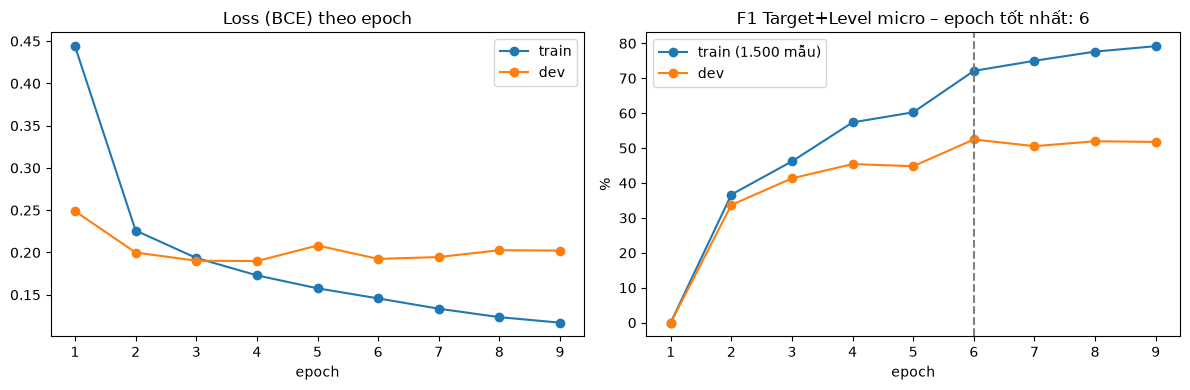

In [11]:
# Gom log theo epoch: dòng có "loss" là log train, dòng có "eval_dev_..." / "eval_train_sub_..." là log đánh giá
rows = collections.defaultdict(dict)
for h in trainer.state.log_history:
    e = int(round(h.get("epoch", 0)))
    for key, name in [("loss", "train_loss"), ("eval_dev_loss", "dev_loss"),
                      ("eval_train_sub_f1_tl", "F1 train"), ("eval_dev_f1_tl", "F1 dev")]:
        if key in h:
            rows[e][name] = h[key]
hist = pd.DataFrame([{"epoch": e, **v} for e, v in sorted(rows.items()) if "F1 dev" in v])
display(hist.round(3))
best_ep = int(hist.loc[hist["F1 dev"].idxmax(), "epoch"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist["epoch"], hist["train_loss"], "o-", label="train"); ax[0].plot(hist["epoch"], hist["dev_loss"], "o-", label="dev")
ax[0].set_title("Loss (BCE) theo epoch"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist["epoch"], hist["F1 train"], "o-", label="train (1.500 mẫu)"); ax[1].plot(hist["epoch"], hist["F1 dev"], "o-", label="dev")
ax[1].axvline(best_ep, ls="--", color="gray"); ax[1].set_title(f"F1 Target+Level micro – epoch tốt nhất: {best_ep}")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("%"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / f"{MODEL_KEY}_learning_curve.png"); plt.show()

## 8. `trainer.evaluate()` trên dev, chọn ngưỡng trên dev, rồi `trainer.predict()` trên test (một lần)
Script gốc dùng ngưỡng cố định logit > 0 (sigmoid 0,5). Tài liệu môn học (mục 4 – Precision-Recall trade-off) khuyên **chọn ngưỡng trên tập Validation**:
thử các ngưỡng 0,2 → 0,6 trên dev, lấy ngưỡng cho F1 dev cao nhất, rồi mới áp dụng cho test.

In [12]:
print("DEV (ngưỡng 0,5 như script):", trainer.evaluate(eval_dataset=eval_dataset, metric_key_prefix="dev"))

dev_out = trainer.predict(eval_dataset)
Ydv = common.label_matrix(dev)
thr_table = pd.DataFrame([{"ngưỡng": t, "F1 dev": common.micro_prf(decode(dev_out.predictions, t)[0], Ydv)["f1"] * 100}
                          for t in np.round(np.arange(0.2, 0.61, 0.05), 2)])
display(thr_table.round(2).T)
THR = float(thr_table.loc[thr_table["F1 dev"].idxmax(), "ngưỡng"])
print("=> Ngưỡng chọn trên dev:", THR)

pred_out = trainer.predict(predict_dataset, metric_key_prefix="test")   # như script: trainer.predict(...)
pred_te, prob_te = decode(pred_out.predictions, THR)
Yte = common.label_matrix(test)
res_test = common.summarize(pred_te, Yte, prob_te)
display(pd.DataFrame({MODEL_KEY: res_test}).T)
display(common.per_target_report(pred_te, Yte))
common.print_classification_reports(pred_te, Yte)

{'dev_loss': '0.1924', 'dev_f1_tl': '52.48', 'dev_f1_target': '65.13', 'dev_paper_f1_tl': '43.11', 'dev_runtime': '1.219', 'dev_samples_per_second': '984.9', 'dev_steps_per_second': '15.58', 'epoch': '9'}
DEV (ngưỡng 0,5 như script): {'dev_loss': 0.1924326866865158, 'dev_f1_tl': 52.47524752475247, 'dev_f1_target': 65.13437057991513, 'dev_paper_f1_tl': 43.10813786987279, 'dev_runtime': 1.2194, 'dev_samples_per_second': 984.936, 'dev_steps_per_second': 15.582, 'epoch': 9.0}


,0,1,2,3,4,5,6,7,8
ngưỡng,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60
F1 dev,54.19,54.75,55.16,54.76,54.66,53.69,52.48,51.44,49.67


=> Ngưỡng chọn trên dev: 0.3


,F1 T+L micro,P T+L micro,R T+L micro,F1 Target micro,F1 T+L (paper),F1 Target (paper),Macro-F1 TB 5 target,Toxic F1,Toxic ROC-AUC,Toxic PR-AUC,Recall hate
phobert,55.25,52.89,57.84,71.71,49.21,66.27,38.54,79.63,86.76,86.08,69.62


,target,macro_P,macro_R,macro_F1,số mẫu có nhắc
0,individual,51.26,51.95,50.87,1398
1,groups,49.51,49.59,46.95,769
2,religion/creed,24.92,25.00,24.96,6
3,race/ethnicity,32.24,34.99,33.52,129
4,politics,34.06,40.28,36.39,89


===== individual =====
              precision    recall  f1-score   support

        none      0.366     0.221     0.276       402
       clean      0.697     0.798     0.744       618
   offensive      0.458     0.407     0.431       324
        hate      0.528     0.651     0.583       456

    accuracy                          0.562      1800
   macro avg      0.513     0.519     0.509      1800
weighted avg      0.538     0.562     0.543      1800

===== groups =====
              precision    recall  f1-score   support

        none      0.664     0.583     0.621      1031
       clean      0.454     0.685     0.546       356
   offensive      0.419     0.141     0.211       185
        hate      0.443     0.575     0.500       228

    accuracy                          0.557      1800
   macro avg      0.495     0.496     0.469      1800
weighted avg      0.569     0.557     0.549      1800

===== religion/creed =====
              precision    recall  f1-score   support

      

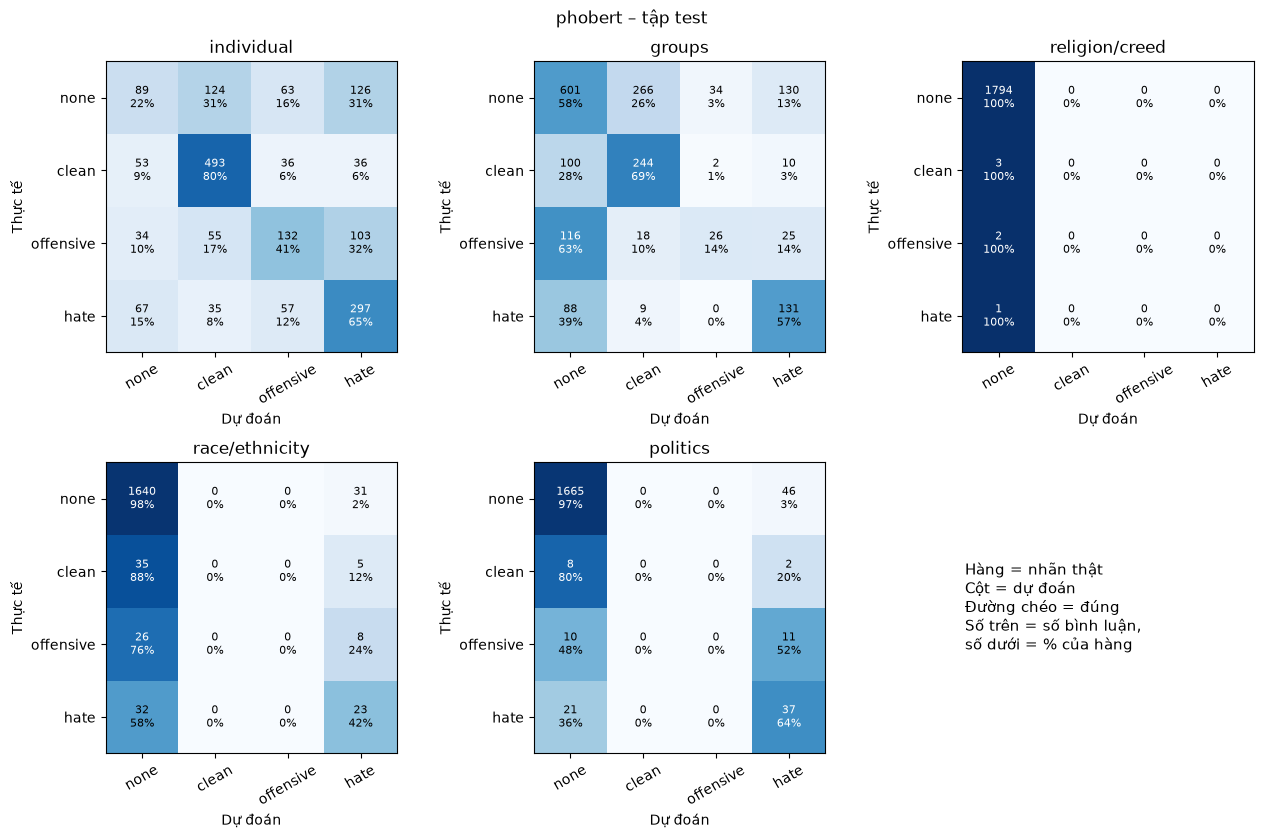

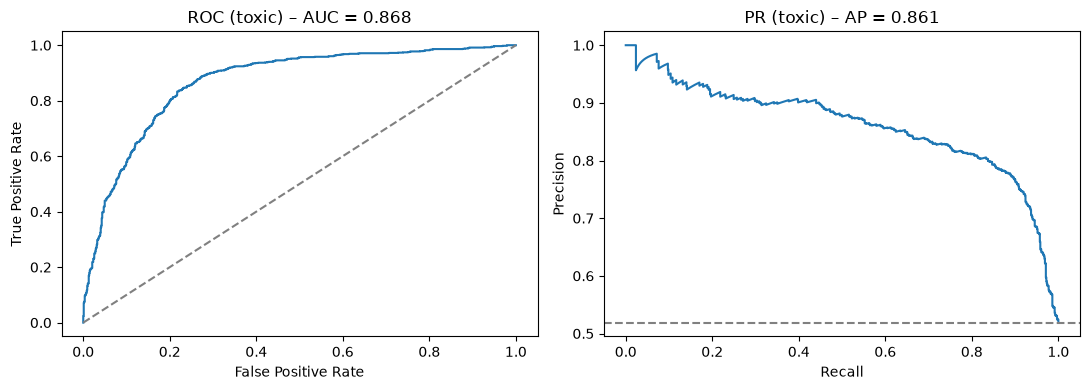

In [13]:
fig = common.plot_confusion_matrices(pred_te, Yte, f"{MODEL_KEY} – tập test")
fig.savefig(OUT_DIR / f"{MODEL_KEY}_confusion_test.png"); plt.show()

from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
y = (Yte >= 2).any(1).astype(int); score = prob_te[:, :, 2:].sum(2).max(1)
fpr, tpr, _ = roc_curve(y, score); p, r, _ = precision_recall_curve(y, score)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "--", color="gray"); ax[0].set_title(f"ROC (toxic) – AUC = {roc_auc_score(y, score):.3f}")
ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate")
ax[1].plot(r, p); ax[1].axhline(y.mean(), ls="--", color="gray"); ax[1].set_title(f"PR (toxic) – AP = {average_precision_score(y, score):.3f}")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
plt.tight_layout(); plt.savefig(OUT_DIR / f"{MODEL_KEY}_roc_pr_test.png"); plt.show()

### So sánh với baseline (Notebook 1) và với paper
Cột "(paper)" tính đúng theo code của nhóm tác giả → so được với số trong bài báo; "micro" là chỉ số chính.

,F1 T+L micro,P T+L micro,R T+L micro,F1 Target micro,F1 T+L (paper),F1 Target (paper),Macro-F1 TB 5 target,Toxic F1,Recall hate,Toxic ROC-AUC,Toxic PR-AUC
Dummy (most_frequent),29.49,34.33,25.85,66.71,28.70,66.38,20.88,0.00,0.00,NaN,NaN
Dummy (stratified),21.40,21.27,21.54,59.73,20.14,56.00,24.94,55.56,38.54,NaN,NaN
TF-IDF + LR,51.96,48.84,55.50,73.81,48.51,69.46,42.51,78.65,70.49,85.78,85.51
ViSoBERT (đặc trưng) + LR,41.62,36.97,47.60,69.12,39.72,65.93,40.90,73.86,66.67,75.47,72.30
visobert,55.67,53.40,58.13,75.01,51.62,71.81,38.09,78.72,69.10,85.19,84.18
phobert,55.25,52.89,57.84,71.71,49.21,66.27,38.54,79.63,69.62,86.76,86.08


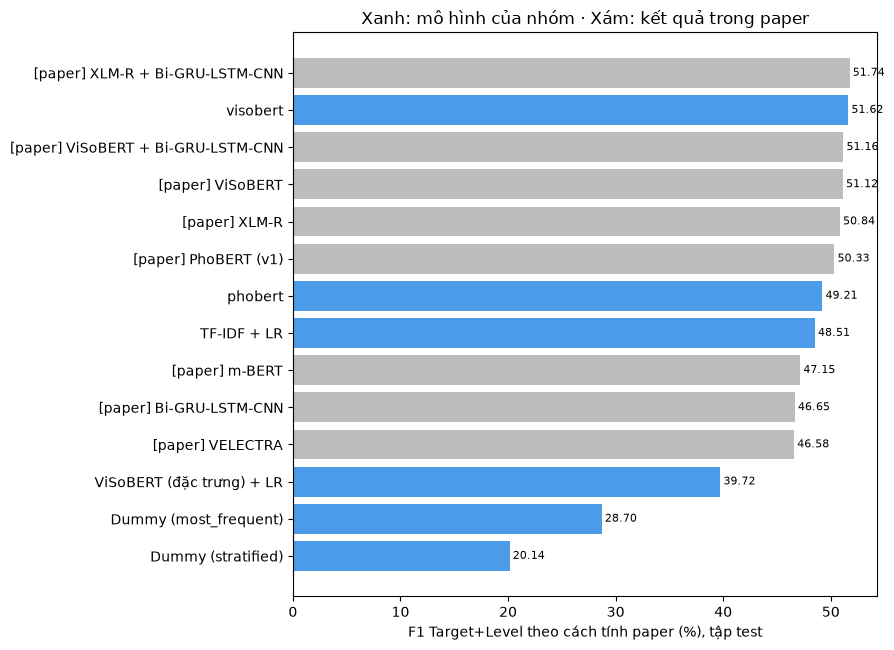

In [14]:
pd.DataFrame({MODEL_KEY: res_test}).T.to_csv(OUT_DIR / f"{MODEL_KEY}_test_results.csv", encoding="utf-8-sig")
files = [OUT_DIR / "baseline_test_results.csv"] + [OUT_DIR / f"{k}_test_results.csv" for k in MODELS]
compare = pd.concat([pd.read_csv(f, index_col=0) for f in files if f.exists()])
display(compare)
compare.to_csv(OUT_DIR / "comparison_test.csv", encoding="utf-8-sig")

allr = {**{f"[paper] {k}": v for k, v in common.PAPER_RESULTS.items()}, **compare["F1 T+L (paper)"].to_dict()}
names = sorted(allr, key=allr.get)
fig, ax = plt.subplots(figsize=(9, 0.4 * len(names) + 1))
ax.barh(names, [allr[n] for n in names], color=["#bdbdbd" if n.startswith("[paper]") else "#4c9be8" for n in names])
for i, n in enumerate(names): ax.text(allr[n] + 0.3, i, f"{allr[n]:.2f}", va="center", fontsize=8)
ax.set_xlabel("F1 Target+Level theo cách tính paper (%), tập test"); ax.set_title("Xanh: mô hình của nhóm · Xám: kết quả trong paper")
plt.tight_layout(); plt.savefig(OUT_DIR / "comparison_paper.png"); plt.show()

## 9. Phân tích lỗi (trên dev) – theo khung *Error analysis* của `02_classification.ipynb`
Khung lấy từ notebook chương 2 của sách *Natural Language Processing with Transformers* (nhóm tác giả Hugging Face,
[github.com/nlp-with-transformers/notebooks](https://github.com/nlp-with-transformers/notebooks), Apache-2.0) – cùng khung với phần phân tích lỗi ở Notebook 1.
Ý tưởng: tính **loss của từng bình luận** (`forward_pass_with_label()`), rồi sắp xếp:
- **loss cao nhất** → mô hình sai mà rất tự tin, hoặc **nhãn có thể bị gán sai** (dữ liệu nhiễu);
- **loss thấp nhất** → mô hình chắc chắn nhất; xem nó có "học vẹt" theo từ khóa không.

**Thay đổi so với khung:** bài toán ở đây là multi-label nên dùng đúng hàm loss lúc huấn luyện là `binary_cross_entropy_with_logits`
(cộng trên 15 nhãn) thay cho `cross_entropy`; logit của dev đã có từ `trainer.predict()` ở mục 8 nên không cần chạy lại mô hình.

In [15]:
# ===== 9. Loss của từng bình luận (khung: forward_pass_with_label() trong 02_classification.ipynb) =====
import collections
import torch
from torch.nn.functional import binary_cross_entropy_with_logits

logits = dev_out.predictions[0] if isinstance(dev_out.predictions, tuple) else dev_out.predictions
loss = binary_cross_entropy_with_logits(torch.tensor(logits, dtype=torch.float32),
                                        torch.tensor(dev_out.label_ids, dtype=torch.float32),
                                        reduction="none").sum(1).numpy()      # (N,) loss từng bình luận
pred_dv, prob_dv = decode(logits, THR)

# Khung: df_test = emotions_encoded["validation"][:][["text", "label", "predicted_label", "loss"]]
df_dev = dev[["content"]].copy()
df_dev["label"] = [common.levels_to_text(r) for r in Ydv]                # nhãn thật
df_dev["predicted_label"] = [common.levels_to_text(r) for r in pred_dv]  # mô hình đoán
df_dev["loss"] = loss.round(3)
df_dev["số target sai"] = (pred_dv != Ydv).sum(1)
df_dev.to_csv(OUT_DIR / f"{MODEL_KEY}_errors_dev.csv", encoding="utf-8-sig", index=False)

# Thống kê bổ sung (ngoài khung): cặp nhầm lẫn của target individual, tỷ lệ sai theo độ dài
pairs = collections.Counter((LEVELS[a], LEVELS[b]) for a, b in zip(Ydv[:, 0], pred_dv[:, 0]) if a != b)
print("individual – nhầm (thật -> đoán) nhiều nhất:", pairs.most_common(5))
bins = pd.cut(dev["content"].str.split().str.len(), [0, 5, 10, 20, 40, 1000], labels=["1-5", "6-10", "11-20", "21-40", ">40"])
print("% bình luận có target sai theo độ dài:", ((df_dev["số target sai"] > 0).groupby(bins, observed=True).mean() * 100).round(1).to_dict())
worst = pd.Series(Ydv.max(1)).map(dict(enumerate(LEVELS)))            # mức nặng nhất của nhãn thật
print("Loss trung bình theo mức nặng nhất của nhãn thật:",
      pd.Series(loss.astype(float)).groupby(worst).mean().reindex(LEVELS).round(3).to_dict())
pd.set_option("display.max_colwidth", 80)

individual – nhầm (thật -> đoán) nhiều nhất: [(('none', 'hate'), 88), (('none', 'clean'), 82), (('offensive', 'hate'), 69), (('clean', 'none'), 48), (('hate', 'none'), 37)]
% bình luận có target sai theo độ dài: {'1-5': 65.8, '6-10': 69.0, '11-20': 72.8, '21-40': 72.4, '>40': 81.4}
Loss trung bình theo mức nặng nhất của nhãn thật: {'none': 2.072, 'clean': 2.162, 'offensive': 4.187, 'hate': 3.407}


**10 bình luận có loss cao nhất** (khung: `df_test.sort_values("loss", ascending=False).head(10)`)

In [16]:
df_dev.sort_values("loss", ascending=False).head(10)

,content,label,predicted_label,loss,số target sai
671,"Tui đổi hộ khẩu, phải đổi CMND kèm theo một tờ giấy A4 xác nhận thay đổi số ...","individual:hate, groups:hate, race/ethnicity:offensive, politics:offensive","individual:clean, groups:clean",22.240999,4
1014,Cổ động viên quảng ninh nhưng rất thích chất cổ động viên hải phòng💐,"individual:hate, groups:hate, race/ethnicity:hate","individual:clean, groups:clean",15.807000,3
1094,"Ngọc Hải ê, biểu tượng cl của m thành trend bên hàn quốc luôn r kìa..","individual:hate, groups:hate, race/ethnicity:hate",individual:clean,13.875000,3
668,Tôi đang xem Hài hay phóng sự đây admin,"individual:hate, groups:hate","individual:clean, groups:clean",13.394000,2
487,Lỡ rồi múc luôn đi. Mấy ảnh về lấy tiền của dân mua lại =]],"individual:hate, politics:hate","individual:clean, groups:clean",13.007000,3
943,Báo lá gì đây :v lá cải thì nhẹ quá,"individual:hate, groups:hate","individual:clean, groups:clean",12.932000,2
318,Dậy thì không thành công ☺,"individual:hate, groups:hate","individual:clean, groups:clean",12.874000,2
131,"Mình sống ở cái nôi của CS,nhưng hàng năm cứ đến những ngày này,ở HN,Hải phò...","individual:clean, groups:clean, religion/creed:clean, race/ethnicity:clean, ...",(không nhắc target),12.402000,5
760,Stupid cực mạnh,"individual:hate, groups:hate","individual:clean, groups:clean",12.285000,2
750,Con trai cưng của độ thích cắn kẹo hương cam 😂,"individual:hate, groups:offensive","individual:clean, groups:clean",12.277000,2


**10 bình luận có loss thấp nhất** (khung: `df_test.sort_values("loss", ascending=True).head(10)`)

In [17]:
df_dev.sort_values("loss", ascending=True).head(10)

,content,label,predicted_label,loss,số target sai
794,😂😂😂🙏,(không nhắc target),(không nhắc target),0.470,0
985,:)(,(không nhắc target),(không nhắc target),0.476,0
992,👍👍👍👍👍👍,(không nhắc target),(không nhắc target),0.477,0
1157,❤️,(không nhắc target),(không nhắc target),0.477,0
944,",..",(không nhắc target),(không nhắc target),0.482,0
6,ói,(không nhắc target),(không nhắc target),0.495,0
1038,Trẻ trâu,(không nhắc target),(không nhắc target),0.503,0
688,Skin mới mọi người ơi,"individual:clean, groups:clean","individual:clean, groups:clean",0.505,0
255,Mua ở đây nhé các ông,"individual:clean, groups:clean","individual:clean, groups:clean",0.508,0
744,Like vì cùng suy nghi😁,"individual:clean, groups:clean","individual:clean, groups:clean",0.508,0


**Gợi ý xếp nhóm lỗi** (đọc 2 bảng trên và đếm): nhãn có vẻ sai · teencode / viết không dấu · mỉa mai, ẩn ý ·
nhầm offensive ↔ hate · nhầm individual ↔ groups · câu quá ngắn, thiếu ngữ cảnh. Toàn bộ dev lưu ở `outputs/<mô hình>_errors_dev.csv`.

## 10. Lưu thông tin và demo dự đoán (offline)

In [18]:
json.dump({"model_key": MODEL_KEY, "hf_id": cfg["hf_id"], "segment": cfg["segment"], "data_source": DATA_SOURCE, "framework": "run_classification.py (transformers v5.19.0)",
           "max_seq_length": max_seq_length, "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE,
           "best_epoch": best_ep, "threshold": THR, "seed": SEED, "test": res_test,
           "versions": {"torch": torch.__version__, "transformers": __import__("transformers").__version__}},
          open(OUTPUT_DIR / "run_info.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("Mô hình đã lưu tại:", OUTPUT_DIR)

def predict_text(texts):
    xs = [common.normalize_text(t) for t in texts]
    if segment:
        xs = [segment(x) for x in xs]
    enc = tokenizer(xs, truncation=True, max_length=max_seq_length, padding=True, return_tensors="pt").to(trainer.model.device)
    with torch.no_grad():
        logits = trainer.model(**enc).logits.float().cpu().numpy()
    pred, _ = decode(logits, THR)
    for t, row in zip(texts, pred):
        found = {TARGETS[j]: LEVELS[v] for j, v in enumerate(row) if v > 0}
        print(t, "->", found or "không nhắc target nào")

predict_text(["bài hát này hay quá, nghe hoài không chán", "thằng này ngu thật", "mấy người đó toàn lừa đảo"])

Mô hình đã lưu tại: D:\ViTHSD\models\phobert
bài hát này hay quá, nghe hoài không chán -> {'individual': 'clean', 'groups': 'clean'}
thằng này ngu thật -> {'individual': 'hate'}
mấy người đó toàn lừa đảo -> {'groups': 'hate'}
